# Task4 — Advanced Train-only EDA
อ่านผลที่คำนวณแล้ว ไม่มีการ train CNN หรืออ่าน Test เมื่อ Run All; `RUN_ANALYSIS=True` จะคำนวณ diagnostics ใหม่จาก Train/OOF เท่านั้น

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'Task4/models/image_training.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
OUT = ROOT / 'Task4/eda/advanced_train_v1'
RUN_ANALYSIS = False
if RUN_ANALYSIS:
    import runpy
    runpy.run_module('Task4.tools.advanced_train_eda', run_name='__main__')
summary = json.loads((OUT / 'summary.json').read_text())
def table(name): return pd.read_parquet(OUT / f'{name}.parquet')
def plot(name): display(Image(filename=str(OUT / 'figures' / f'{name}.png')))

## 1. Integrity, duplicates และ fold leakage

In [2]:
display(summary['integrity'])
display(table('exact_duplicate_groups').head(), table('near_duplicate_groups').head())

{'rows': 31546,
 'unique_ids': 31546,
 'exact_duplicate_groups': 0,
 'exact_conflicting_groups': 0,
 'near_conflicting_groups': 0,
 'exact_cross_fold_groups': 0,
 'near_cross_fold_groups': 0,
 'resolution_counts': {'(230, 120)': 31546}}

,sha256,rows,classes,folds


,near_group,rows,classes,folds
0,136,2,1,1
1,605,2,1,1
2,13952,2,1,1
3,16824,2,1,1


## 2. Class imbalance และ OOF confusion

,class,n,precision,recall,F1,errors
0,7-11k,12429,0.989389,0.990265,0.989827,121
1,fiveN,4407,0.979977,0.977309,0.978641,100
2,freefried,5596,0.989076,0.986955,0.988014,73
3,pube,5926,0.982581,0.980425,0.981502,116
4,roblock,3188,0.962352,0.970201,0.966261,95


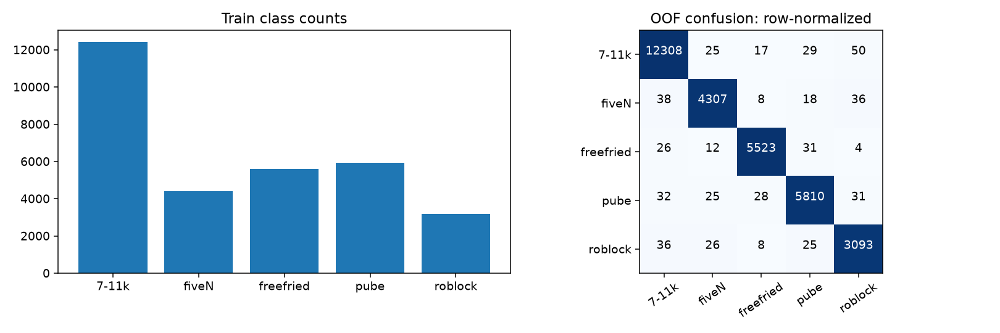

In [3]:
display(table('class_metrics'))
plot('class_confusion')

## 3. Quality slices: error rates + class composition + uncertainty

,feature,bin,n,errors,error_rate,ci_low,ci_high,class_mix_expected_error,excess_error
88,gradient_y,"(0.00317, 0.0311]",6310,216,0.034231,0.030021,0.039009,0.016455,0.017776
78,saturation_std,"(0.0023, 0.0566]",6310,189,0.029952,0.026024,0.034453,0.014413,0.015539
83,gradient_x,"(0.0031399999999999996, 0.0272]",6310,202,0.032013,0.027946,0.036649,0.016662,0.015351
93,hf_abs,"(0.00208, 0.0177]",6310,199,0.031537,0.027502,0.036143,0.016622,0.014916
98,hf_std,"(0.00288, 0.0257]",6310,196,0.031062,0.027058,0.035636,0.016585,0.014476
73,saturation_mean,"(0.00019000000000000006, 0.0739]",6310,178,0.028209,0.024402,0.032590,0.014244,0.013965
25,std_b,"(0.00403, 0.119]",6310,180,0.028526,0.024697,0.032929,0.016003,0.012523
15,std_r,"(0.0037, 0.119]",6310,173,0.027417,0.023666,0.031743,0.016048,0.011369
20,std_g,"(0.00366, 0.119]",6310,172,0.027258,0.023519,0.031573,0.016006,0.011252
60,lum_q99,"(0.0265, 0.57]",6313,165,0.026137,0.022480,0.030370,0.016151,0.009986


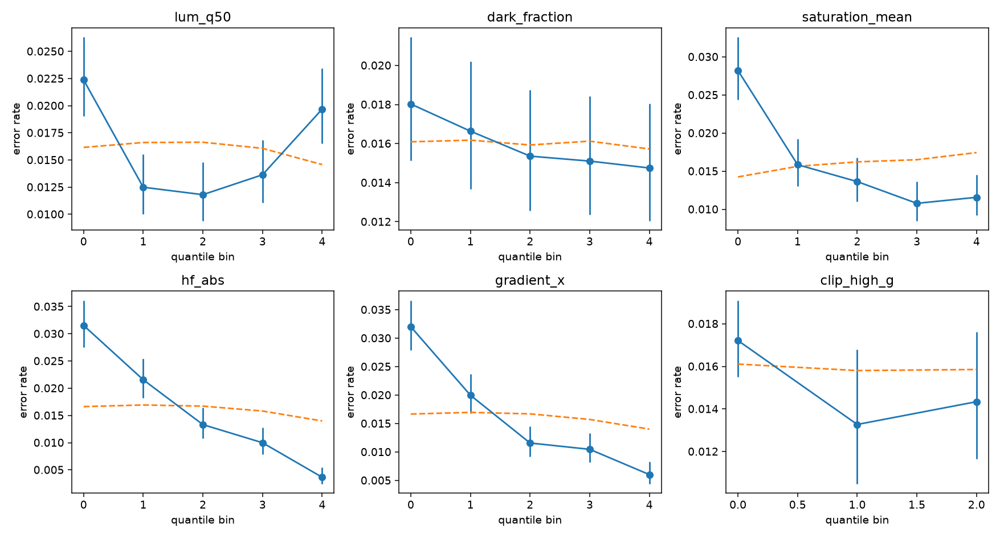

In [4]:
display(table('quality_slices').sort_values('excess_error', ascending=False).head(15))
plot('quality_slices')

## 4. Quality clusters (ไม่ใช่ semantic clusters)

,quality_cluster,n,errors,error_rate,confidence,router_weight
0,0,4202,48,0.011423,0.983712,0.649233
1,1,5504,90,0.016352,0.976608,0.665803
2,2,3895,41,0.010526,0.987805,0.597976
3,3,4015,105,0.026152,0.970790,0.634835
4,4,5683,77,0.013549,0.986055,0.660477
5,5,1275,21,0.016471,0.976865,0.571128
6,6,4019,23,0.005723,0.991763,0.595522
7,7,2953,100,0.033864,0.952669,0.670023


,quality_cluster,7-11k,fiveN,freefried,pube,roblock
0,0,0.269158,0.071633,0.123037,0.400048,0.136126
1,1,0.331759,0.162246,0.197493,0.220385,0.088118
2,2,0.525802,0.151220,0.165597,0.076508,0.080873
3,3,0.425405,0.103861,0.181818,0.176090,0.112827
4,4,0.314623,0.177547,0.225585,0.196375,0.085870
5,5,0.516863,0.130980,0.120000,0.123922,0.108235
6,6,0.518039,0.127146,0.170192,0.054491,0.130132
7,7,0.401964,0.176092,0.168642,0.180833,0.072469


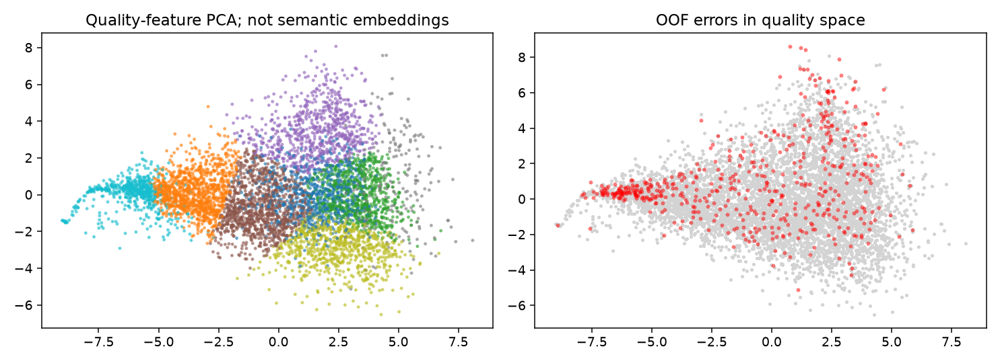

In [5]:
display(table('quality_clusters'), table('cluster_class_mix'))
plot('quality_clusters')

## 5. Calibration และ selective risk

{'accuracy': 0.9839916312686235,
 'macro_F1': 0.9808489161304823,
 'errors': 505,
 'ece10': 0.004584297195812837,
 'nll': 0.051239008997397875,
 'brier_multiclass': 0.024934066888958082,
 'high_conf_wrong_ge_095': 32}

,bin,n,confidence,accuracy
0,2,2,0.294842,0.500000
1,3,46,0.364062,0.521739
2,4,147,0.455883,0.435374
3,5,274,0.548618,0.620438
4,6,308,0.649766,0.681818
5,7,392,0.752423,0.826531
6,8,626,0.854307,0.880192
7,9,29751,0.996197,0.998185


,coverage,error_rate,rows
0,0.25,0.000000,7886
1,0.50,0.000000,15773
2,0.75,0.000127,23659
3,0.90,0.000740,28391
4,0.95,0.002603,29968
5,1.00,0.016008,31546


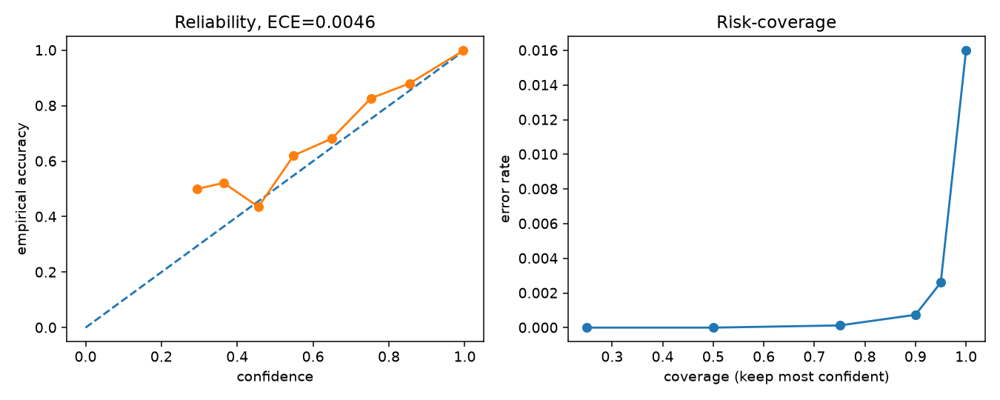

In [6]:
display({k: summary[k] for k in ['accuracy','macro_F1','errors','ece10','nll','brier_multiclass','high_conf_wrong_ge_095']})
display(table('reliability'), table('risk_coverage'))
plot('calibration')

## 6. Expert complementarity และ router failure analysis

{'disagreements': 514,
 'both_wrong': 381,
 'only_compound_correct': 223,
 'only_sampler_correct': 223,
 'ensemble_errors': 505,
 'router_changed': 94,
 'router_fixes': 25,
 'router_breaks': 57}

,class_name,disagree,both_wrong,only_compound_correct,only_sampler_correct,error
0,7-11k,135,86,55,63,121
1,fiveN,80,70,32,37,100
2,freefried,72,62,42,22,73
3,pube,129,88,40,70,116
4,roblock,98,75,54,31,95


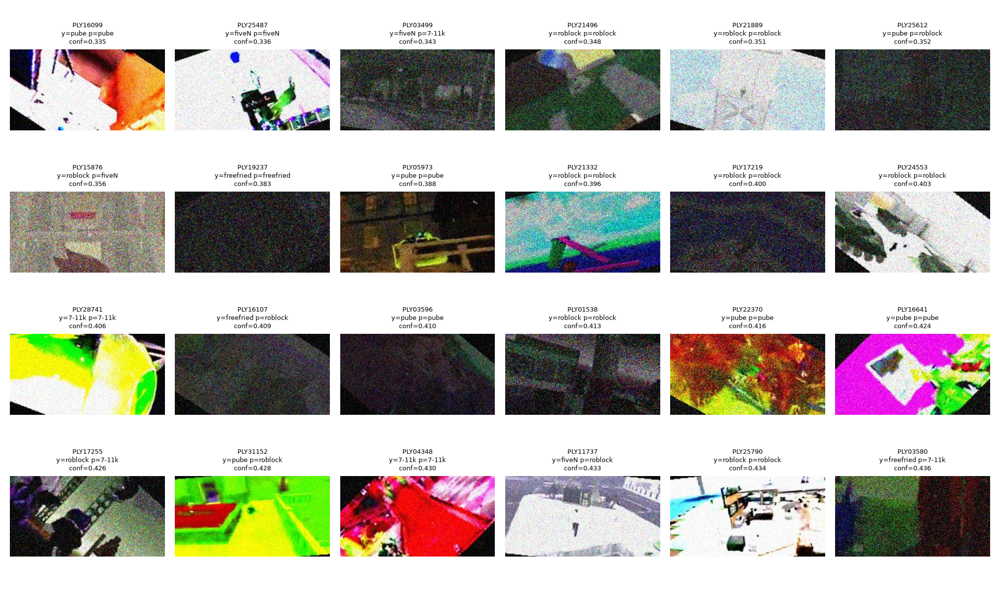

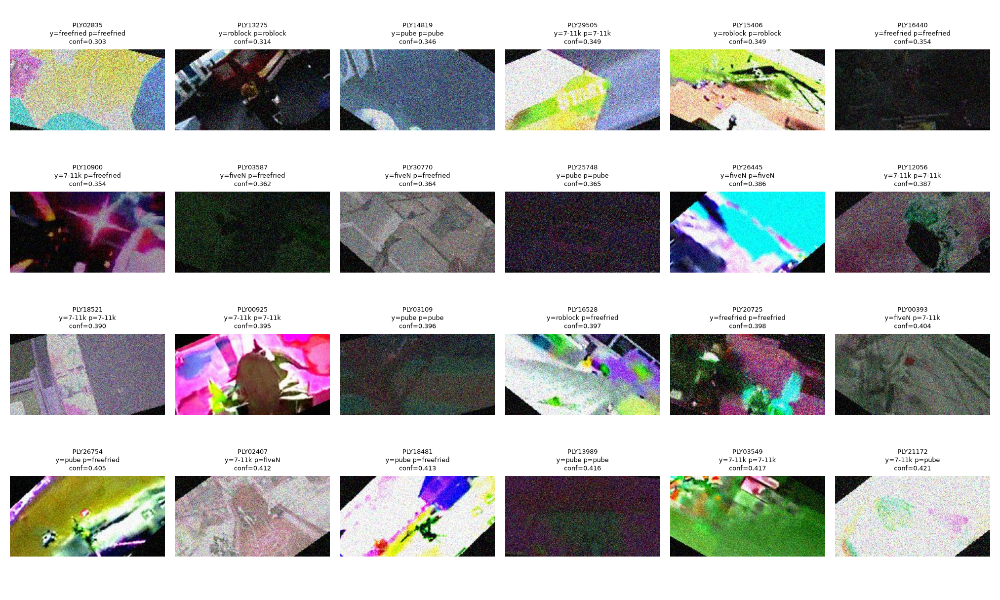

In [7]:
display(summary['complementarity'])
display(table('expert_overlap_by_class'))
plot('compound_only_correct')
plot('sampler_only_correct')

## 7. Human review: มั่นใจผิด ≠ label ผิด

,id,class_name,prediction,confidence,fold
0,PLY30013,roblock,0,0.999416,4
1,PLY05231,roblock,0,0.999204,4
2,PLY30813,fiveN,4,0.999143,4
3,PLY30775,freefried,0,0.998477,5
4,PLY02877,roblock,0,0.998245,5
5,PLY16238,pube,4,0.991154,3
6,PLY20965,fiveN,0,0.989956,3
7,PLY13454,7-11k,4,0.987417,2
8,PLY20117,pube,4,0.983194,4
9,PLY06575,pube,4,0.982818,5


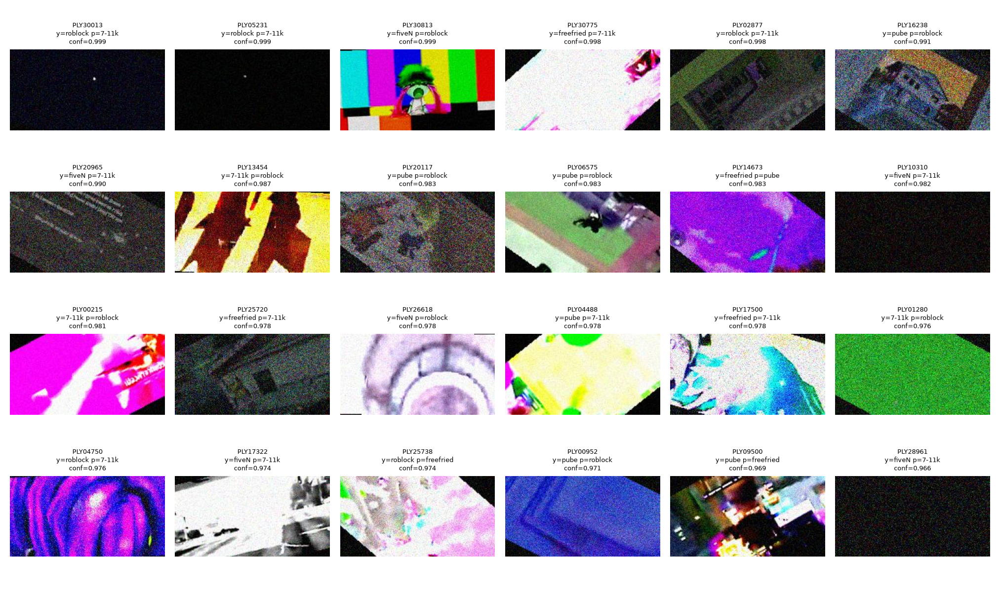

In [8]:
display(table('high_confidence_error_review')[['id','class_name','prediction','confidence','fold']].head(32))
plot('high_confidence_errors')

## 8. Quality predicts error? Diagnostic only

In [9]:
display(summary['error_predictability'])
print('Error prevalence:', summary['error_prevalence'])

Error prevalence: 0.016008368731376402


{'class_only': {'roc_auc': 0.6022691164448425,
  'average_precision': 0.022361703787398116},
 'quality_and_class': {'roc_auc': 0.7165533543786388,
  'average_precision': 0.0409372483156855}}

## 9. Findings, limitations และลำดับการทดลองต่อ

In [10]:
display(Markdown((ROOT / 'docs/task4-advanced-eda-note.md').read_text()))

# Task4 advanced Train-only EDA

วิเคราะห์ภาพ Train 31,546 ภาพกับ predictions แบบ OOF 5 folds ของ compound_supervised6 และ heavy_sampler18 โดยใช้ ensemble 50/50 เป็นจุดอ้างอิง ไม่อ่าน Test และไม่เปลี่ยน labels/model weights

## ข้อค้นพบพร้อมหลักฐาน

1. **Original Train OOF ใกล้เพดานแล้ว:** pooled macro F1 = 0.980849, accuracy = 0.983992, ผิด 505/31,546 ภาพ ตัวเลขนี้เป็น pooled OOF ไม่ใช่ mean fold และไม่ใช่ Public score ดังนั้น augmentation เพิ่มไม่จำเป็นต้องทำให้คะแนนรวมกระโดด
2. **ไม่พบ exact duplicates หรือกลุ่ม near-duplicate ที่ข้าม folds ใน cache เดิม** และไม่พบกลุ่มเหล่านี้ที่ label ขัดกัน ไม่ได้พิสูจน์ว่าไม่มี semantic duplicates; ขึ้นกับวิธีสร้าง near_group เดิม ภาพทั้งหมด 230×120
3. **Class imbalance มีจริง แต่ไม่ใช่คำอธิบายทั้งหมด:** 7-11k 12,429 ภาพ เทียบ Roblock 3,188 ภาพ (ประมาณ 3.90 เท่า) F1 ของ Roblock ต่ำสุด 0.966261; FiveN 0.978641; PUBE 0.981502; Free Fried 0.988014; 7-11k 0.989827 โมเดลเดิมมี weighting/sampling แล้ว
4. **รายละเอียดภาพสัมพันธ์กับ error มากกว่าการคิดว่า noise หนักอย่างเดียว:** quintile gradient_y ต่ำสุดผิด 216/6,310 = 3.423% เทียบภาพรวม 1.601%; ค่าเฉลี่ยที่คาดจากส่วนผสมคลาสใน slice นี้ 1.646% ส่วน saturation_std ต่ำสุดผิด 189/6,310 = 2.995% เทียบ class-mix expected 1.441% เป็นความสัมพันธ์เชิงพรรณนา ไม่พิสูจน์สาเหตุ และ gradient วัดรวมทั้ง texture, contrast, noise
5. **สองโมเดลยังมี blind spots ร่วมกัน:** ผิดพร้อมกัน 381 ภาพ แต่ละตัวถูกเพียงตัวเดียวเท่ากัน 223 ภาพ โมเดลเห็นต่างกัน 514 ภาพ การเปลี่ยนน้ำหนักไม่สามารถแก้ทุกภาพที่ทั้งสองทายผิดได้ (soft blending อาจเลือกคลาสที่สามได้ จึงไม่ใช่ theoretical hard ceiling)
6. **Quality router ยังเลือก expert ไม่ตรงกับความสามารถจริง:** เปลี่ยนคำตอบ 94 ภาพ แก้ถูก 25 แต่เปลี่ยนจากถูกเป็นผิด 57; อีก 12 ยังผิด การรู้ว่าภาพคล้าย synthetic corruption ไม่เท่ากับรู้ว่า expert ตัวไหนจะทายถูก
7. **Confidence ไม่ใช่หลักฐานว่า label ผิด:** มี 32 ภาพที่มั่นใจ ≥95% แต่ผิด ภาพตัวอย่างมีทั้งมืดมาก สี clip หมุน และ noise จนรายละเอียดหาย บางภาพอาจเป็นฉาก/overlay ที่กำกวม ต้องตรวจด้วยคน ห้าม relabel จาก prediction โดยตรง
8. **Quality feature มี signal แต่ยังไม่พอใช้เป็นตัวเลือกโมเดล:** diagnostic cross-fold logistic regression ทำนาย error ได้ ROC AUC 0.7166 เทียบ class-only 0.6023 แต่ average precision เพียง 0.0409 เทียบ error prevalence 0.0160 และใช้ true class จึงเป็นการอธิบาย error ไม่ใช่ router ที่นำไปใช้ทำนาย Test ได้

## แนวทางทดลองที่ได้จาก EDA (ยังไม่ได้ฝึก)

- **อันดับแรก: information-preserving preprocessing ablation** ใช้ split เดิม เปรียบเทียบ resize/pad เดิมกับ aspect-ratio-preserving rectangular input และ mild contrast normalization แบบกำหนดคงที่ ตรวจ low-gradient/low-saturation slices แยกทุกคลาส เปลี่ยนทีละอย่าง; หลีกเลี่ยง denoise หนักที่อาจลบรายละเอียดที่เหลือน้อย ภาพเดิม 230×120 ถูก resize เป็น 224×112 แล้ว pad จน 224×224: padding กินครึ่งพื้นที่ แต่ไม่ได้ยืนยันว่าเป็นต้นเหตุ
- **อันดับสอง: เพิ่ม representation diversity** ทดสอบ backbone ต่างตระกูลหนึ่งตัวด้วย augmentation ที่ดีที่สุดเดิม วัดทั้ง macro F1 และจำนวน shared errors ที่ลดลง ปัจจุบัน experts เป็น ResNet18 เหมือนกัน เปลี่ยนแค่ augmentation/weighting จึงอาจไม่ได้แก้การมองภาพแบบเดียวกัน ต้องพิสูจน์ด้วย paired OOF
- **อันดับสาม: sampling ตาม class × quality** ทดลองให้น้ำหนักภาพยากจาก quality ที่คำนวณเฉพาะ training fold แบบมีเพดาน แทนเพิ่ม severity ให้ทุกรูป โดยไม่เลือก training samples จาก held-out errors หลีกเลี่ยง oversample ภาพที่แทบไม่มีข้อมูล
- ยังไม่ควรเพิ่ม class bias หรือ synthetic-quality router ต่อทันที: ผลเดิมชี้ว่ามี trade-off และ router ทำ original errors เพิ่ม; การเปลี่ยนจำนวน alerts/คะแนนรวม Task5 ไม่เกี่ยวกับการวิเคราะห์นี้

## วิธีอ่านผลและข้อจำกัด

- Error slices 27 features × quintiles เป็น exploratory multiple comparisons, Wilson CI ไม่ได้ปรับ dependency ของ near groups หรือ multiple testing
- Class-mix expected error เป็น descriptive standardization ไม่ใช่ causal adjustment
- KMeans/PCA ใช้ image-quality statistics 27 ตัว ไม่ใช่ semantic embeddings; ห้ามตีความ cluster เป็นเกม/ชนิด cheat/กลุ่ม label ใหม่
- OOF ชุดนี้ถูกใช้พัฒนาหลายรอบแล้ว จึงไม่ใช่ independent final validation; error-predictability stage ก็ไม่ใช่ fully nested model-selection estimate
- ไม่ทราบราย Task บน Public leaderboard จึงยังสรุปไม่ได้ว่า gap ทั้งหมดมาจาก Task4 หรือวิธีต่อไปจะได้ 0.87
- ECE แบบ 10 bins = 0.00458 อาจซ่อนความผิดพลาดในกลุ่มย่อย; ต้องดู reliability, class metrics และภาพผิดร่วมกัน

## หลักวิธีที่เกี่ยวข้อง

Calibration/reliability: Guo et al. (2017), https://proceedings.mlr.press/v70/guo17a.html

การใช้ out-of-sample predictions ช่วยตรวจคุณภาพ label: Northcutt et al., Confident Learning, https://arxiv.org/abs/1911.00068 — งานนี้ทำเพียง review list ไม่ได้ implement Confident Learning และไม่ได้ยืนยัน label ผิด

## Reproduce และ artifacts

รันจาก CPE342-Kaggle: `.venv/bin/python -m Task4.tools.advanced_train_eda`
Notebook: `Task4/Task4_advanced_eda.ipynb`
Evidence: `Task4/eda/advanced_train_v1/` มี parquet, figures, summary.json, sources.json (source hashes)


กราฟ quality slices: เส้นทึบคือ error จริงพร้อม Wilson 95% CI; เส้นประคือ error ที่คาดจากส่วนผสมคลาสใน slice นั้น ทั้งสองเป็น exploratory diagnostics